# Spider-Man Incident Triage: predicting `response_priority`
Fixed seed, test set used once at the end, all preprocessing inside Pipelines (no leakage).

## 1. Setup

In [1]:
import json, re
from pathlib import Path
import joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             ConfusionMatrixDisplay, f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, cross_validate,
                                     cross_val_score, learning_curve, train_test_split)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
np.random.seed(SEED)
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
LABELS = ["Low", "Medium", "High"]          # encoded 0, 1, 2

def show(name):
    plt.tight_layout(); plt.savefig(OUT / name, dpi=120)
    try: get_ipython(); plt.show()          # inside Jupyter/Colab
    except NameError: plt.close()           # plain script

## 2. Load and audit the data

In [2]:
LOCAL = Path("data/spiderman_incident_priority_dataset.csv")
URL = ("https://docs.google.com/spreadsheets/d/1qSQAUSbs_JqvsJ4Ue4u93Ufr_zCntVe32zE8Aq2sS6s"
       "/export?format=csv&gid=938238194")
df = pd.read_csv(LOCAL if LOCAL.exists() else URL)
print("shape:", df.shape)
print("missing values:\n", df.isna().sum()[lambda s: s > 0])
print("duplicate rows:", df.duplicated().sum(), "| duplicate ids:", df.incident_id.duplicated().sum())

shape: (1600, 14)
missing values:
 Series([], dtype: int64)
duplicate rows: 0 | duplicate ids: 0


## 3. Clean

In [3]:
obj = df.select_dtypes(exclude="number").columns
df[obj] = df[obj].apply(lambda s: s.str.strip())             # remove stray spaces
df = df.drop_duplicates().drop_duplicates("incident_id")
df = df.dropna(subset=["response_priority"])
y = df["response_priority"].map({l: i for i, l in enumerate(LABELS)}).astype(int)
X = df.drop(columns=["incident_id", "response_priority"])    # id carries no signal
print(df["response_priority"].value_counts(normalize=True).round(3))

response_priority
Medium    0.703
High      0.156
Low       0.141
Name: proportion, dtype: float64


## 4. Quick EDA

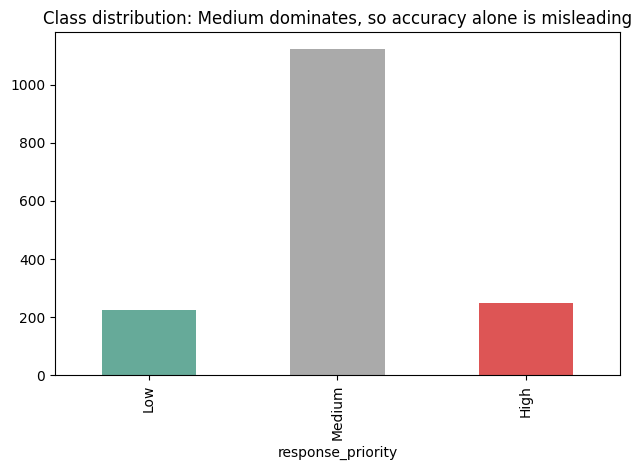

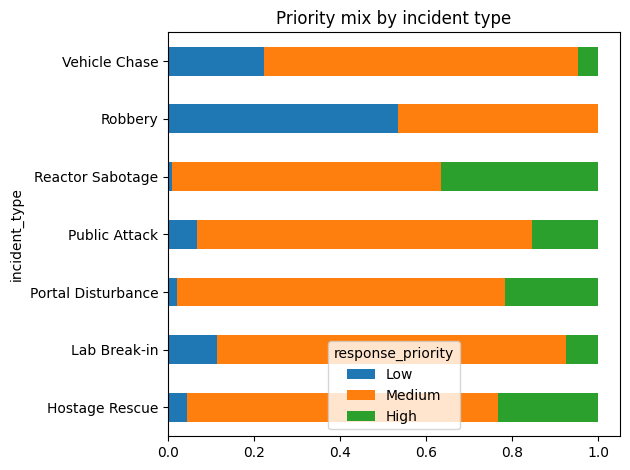

In [4]:
df["response_priority"].value_counts().reindex(LABELS).plot.bar(color=["#6a9", "#aaa", "#d55"])
plt.title("Class distribution: Medium dominates, so accuracy alone is misleading"); show("class_distribution.png")
pd.crosstab(df.incident_type, df.response_priority, normalize="index")[LABELS].plot.barh(stacked=True)
plt.title("Priority mix by incident type"); show("priority_by_incident_type.png")

## 5. Split (stratified) and CV setup. The test set is not touched until step 9

In [5]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
CV = StratifiedKFold(5, shuffle=True, random_state=SEED)
print("train:", ytr.value_counts().sort_index().tolist(), "test:", yte.value_counts().sort_index().tolist())

train: [180, 900, 200] test: [45, 225, 50]


## 6. Preprocessing (fitted only on training folds, because it lives inside the Pipeline)

In [6]:
ORD = {"spider_sense_alert": ["Low", "Moderate", "High"], "backup_status": ["Available", "Delayed", "Unavailable"]}
CAT = ["villain", "incident_type", "location", "weather", "time_of_day"]
NUM = ["civilians_at_risk", "property_damage_level", "web_trap_strength",
       "villain_escape_risk", "response_delay_minutes"]

def make_pre(num=NUM):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("ord", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("enc", OrdinalEncoder(categories=list(ORD.values()),
                                                 handle_unknown="use_encoded_value", unknown_value=-1))]), list(ORD)),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("enc", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CAT),
    ])

def build(clf, num=NUM):
    return Pipeline([("pre", make_pre(num)), ("clf", clf)])

## 7. Baselines + model comparison (cross-validation on the training set only)

In [7]:
models = {
    "Dummy (always Medium)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
    "MLP (neural net)": MLPClassifier((32, 16), max_iter=1000, random_state=SEED),
}
rows = {}
for name, clf in models.items():
    r = cross_validate(build(clf), Xtr, ytr, cv=CV, scoring={"f1": "f1_macro", "bal": "balanced_accuracy"},
                       return_train_score=True)
    rows[name] = {"train macro-F1": r["train_f1"].mean(), "CV macro-F1": r["test_f1"].mean(),
                  "CV std": r["test_f1"].std(), "CV balanced acc": r["test_bal"].mean()}
cv_table = pd.DataFrame(rows).T.round(3)
print(cv_table)

                        train macro-F1  CV macro-F1  CV std  CV balanced acc
Dummy (always Medium)            0.275        0.275   0.000            0.333
Logistic Regression              0.846        0.816   0.025            0.877
Decision Tree                    0.598        0.505   0.034            0.607
Random Forest                    1.000        0.556   0.034            0.508
Hist Gradient Boosting           1.000        0.752   0.013            0.732
MLP (neural net)                 1.000        0.794   0.022            0.784


## 8. Hyperparameter tuning (RandomizedSearchCV on macro-F1)

In [8]:
spaces = {
        "Logistic Regression": {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30], "clf__class_weight": ["balanced", None]},
    "Random Forest": {"clf__n_estimators": [200, 400, 600], "clf__max_depth": [None, 6, 10, 15],
                      "clf__min_samples_leaf": [1, 2, 5], "clf__max_features": ["sqrt", 0.5]},
    "Hist Gradient Boosting": {"clf__learning_rate": [0.03, 0.05, 0.1], "clf__max_depth": [None, 3, 5],
                               "clf__max_iter": [100, 200, 300], "clf__l2_regularization": [0, 1, 5],
                               "clf__min_samples_leaf": [10, 20, 40]},
}
tuned = {}
for name, space in spaces.items():
    s = RandomizedSearchCV(build(clone(models[name])), space, n_iter=15, scoring="f1_macro",
                           cv=CV, random_state=SEED, n_jobs=-1).fit(Xtr, ytr)
    tuned[name + " (tuned)"] = s
    print(f"{name}: best CV macro-F1 = {s.best_score_:.3f} | {s.best_params_}")
chosen = max(tuned, key=lambda k: tuned[k].best_score_)      # chosen on CV, never on test
final = tuned[chosen].best_estimator_
print("\nChosen model:", chosen)

Logistic Regression: best CV macro-F1 = 0.842 | {'clf__class_weight': None, 'clf__C': 30}
Random Forest: best CV macro-F1 = 0.732 | {'clf__n_estimators': 600, 'clf__min_samples_leaf': 5, 'clf__max_features': 'sqrt', 'clf__max_depth': 15}
Hist Gradient Boosting: best CV macro-F1 = 0.777 | {'clf__min_samples_leaf': 20, 'clf__max_iter': 300, 'clf__max_depth': 3, 'clf__learning_rate': 0.1, 'clf__l2_regularization': 5}

Chosen model: Logistic Regression (tuned)


## 9. Final evaluation on the held-out test set (used once)

In [9]:
# Triage cost: rows = true class, cols = predicted class (Low, Medium, High). These numbers are my own assumption:
# missing a High is the worst mistake, over-flagging costs a little.
COST = np.array([[0, 1, 2],
                 [3, 0, 1],
                 [10, 5, 0]])

def evaluate(m):
    p, pr = m.predict(Xte), m.predict_proba(Xte)
    return {"accuracy": accuracy_score(yte, p), "balanced acc": balanced_accuracy_score(yte, p),
            "macro precision": precision_score(yte, p, average="macro", zero_division=0),
            "macro recall": recall_score(yte, p, average="macro"), "macro F1": f1_score(yte, p, average="macro"),
            "High recall": recall_score(yte, p, average=None, labels=[0, 1, 2])[2],
            "ROC-AUC (ovr)": roc_auc_score(yte, pr, multi_class="ovr", average="macro"),
            "triage cost (lower=better)": COST[yte, p].mean()}

fitted = {n: build(c).fit(Xtr, ytr) for n, c in models.items()}
fitted.update({n: s.best_estimator_ for n, s in tuned.items()})
results = pd.DataFrame({n: evaluate(m) for n, m in fitted.items()}).T.sort_values("macro F1", ascending=False).round(3)
print(results)

                                accuracy  balanced acc  macro precision  \
Logistic Regression (tuned)        0.869         0.829            0.819   
Logistic Regression                0.841         0.870            0.767   
MLP (neural net)                   0.822         0.753            0.762   
Hist Gradient Boosting (tuned)     0.806         0.785            0.728   
Hist Gradient Boosting             0.791         0.696            0.722   
Random Forest (tuned)              0.756         0.696            0.689   
Random Forest                      0.775         0.539            0.816   
Decision Tree                      0.612         0.658            0.544   
Dummy (always Medium)              0.703         0.333            0.234   

                                macro recall  macro F1  High recall  \
Logistic Regression (tuned)            0.829     0.823         0.74   
Logistic Regression                    0.870     0.806         0.86   
MLP (neural net)                    

## 10. Confusion matrix, per-class report, overfitting check, errors

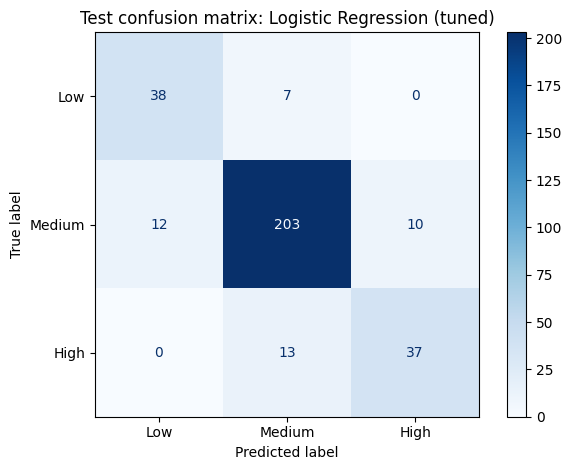

              precision    recall  f1-score   support

         Low       0.76      0.84      0.80        45
      Medium       0.91      0.90      0.91       225
        High       0.79      0.74      0.76        50

    accuracy                           0.87       320
   macro avg       0.82      0.83      0.82       320
weighted avg       0.87      0.87      0.87       320

macro-F1 -> train 0.871 | CV 0.842 | test 0.823


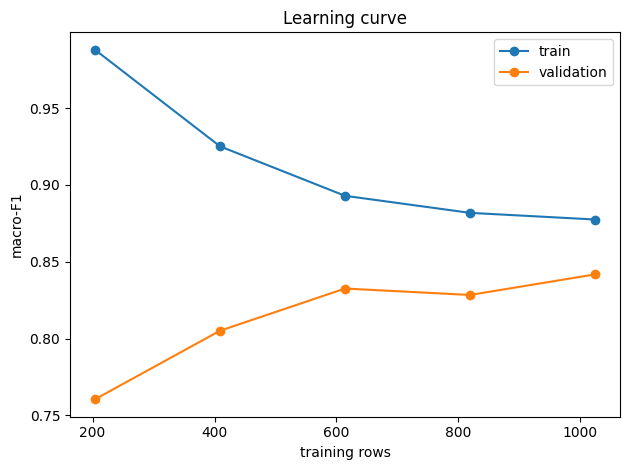

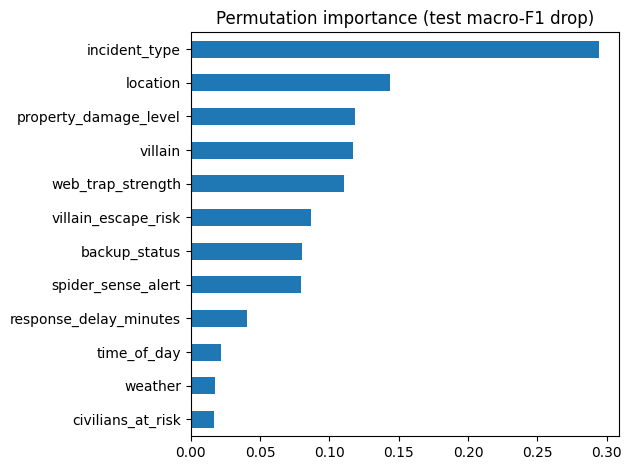

In [10]:
pred = final.predict(Xte)
ConfusionMatrixDisplay.from_predictions(yte, pred, display_labels=LABELS, cmap="Blues")
plt.title(f"Test confusion matrix: {chosen}"); show("confusion_matrix.png")
print(classification_report(yte, pred, target_names=LABELS, zero_division=0))

train_f1 = f1_score(ytr, final.predict(Xtr), average="macro")
print(f"macro-F1 -> train {train_f1:.3f} | CV {tuned[chosen].best_score_:.3f} | test {f1_score(yte, pred, average='macro'):.3f}")
err = Xte.assign(true=[LABELS[i] for i in yte], predicted=[LABELS[i] for i in pred])
err[err.true != err.predicted].to_csv(OUT / "misclassified_test_rows.csv")

sizes, tr, va = learning_curve(final, Xtr, ytr, cv=CV, scoring="f1_macro", shuffle=True,
                               random_state=SEED, train_sizes=np.linspace(0.2, 1, 5))
plt.plot(sizes, tr.mean(1), "o-", label="train"); plt.plot(sizes, va.mean(1), "o-", label="validation")
plt.xlabel("training rows"); plt.ylabel("macro-F1"); plt.legend(); plt.title("Learning curve"); show("learning_curve.png")

pi = permutation_importance(final, Xte, yte, scoring="f1_macro", n_repeats=10, random_state=SEED)
pd.Series(pi.importances_mean, index=Xte.columns).sort_values().plot.barh()
plt.title("Permutation importance (test macro-F1 drop)"); show("feature_importance.png")

## 11. Signature check: is response_delay_minutes safe to use?

In [11]:
# The delay is probably only known after the response starts, so it may not exist when priority is decided.
no_delay = [c for c in NUM if c != "response_delay_minutes"]
with_d = cross_val_score(final, Xtr, ytr, cv=CV, scoring="f1_macro").mean()
without_d = cross_val_score(clone(final).set_params(pre=make_pre(no_delay)), Xtr, ytr, cv=CV, scoring="f1_macro").mean()
print(f"CV macro-F1 with delay: {with_d:.3f} | without delay: {without_d:.3f}")

CV macro-F1 with delay: 0.842 | without delay: 0.832


## 12. Save everything

In [12]:
joblib.dump(final, "model.joblib")
with open(OUT / "final_metrics.json", "w") as f:
    json.dump({"model": chosen, "seed": SEED, **results.loc[chosen].to_dict()}, f, indent=2)
cv_table.to_csv(OUT / "cv_table.csv"); results.to_csv(OUT / "test_results.csv")

def md(d):
    head = "| Model | " + " | ".join(d.columns) + " |\n|" + "---|" * (len(d.columns) + 1)
    return head + "\n" + "\n".join(f"| {i} | " + " | ".join(f"{v:.3f}" for v in r) + " |" for i, r in d.iterrows())

if Path("README.md").exists():                               # keep README metrics in sync with the notebook
    block = f"<!-- METRICS_START -->\n**Final model:** {chosen} (seed {SEED}, held-out test set)\n\n{md(results)}\n<!-- METRICS_END -->"
    txt = Path("README.md").read_text(encoding="utf-8")
    Path("README.md").write_text(re.sub(r"<!-- METRICS_START -->.*<!-- METRICS_END -->", lambda m: block, txt, flags=re.S),
                                 encoding="utf-8")

## Justification
1. What the data looks like (size, feature types, class imbalance).
2. What I compared and the scores.
3. Why the chosen model fits better.
4. Its limits (small/synthetic data, the delay column, imbalance, my assumed cost numbers).
5. Overfitting/underfitting and where the model makes errors.